In [235]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.special import factorial
from scipy import stats
from scipy.optimize import curve_fit

ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
plt.rcParams.update({
    "figure.figsize": (8.2, 4.6),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "font.size": 11,
    "legend.frameon": False,
})

rng = np.random.default_rng(12)

In [236]:
x = np.linspace ( -5 , 5 , 161)
#print(x)

In [237]:
#parametri
B = 20
I = 400
alfa = 0.9
delta = 5.2

E = (np.sinc(alfa * x / np.pi))**2
C = (np.cos(delta * x))**2

mu = B + I * E * C

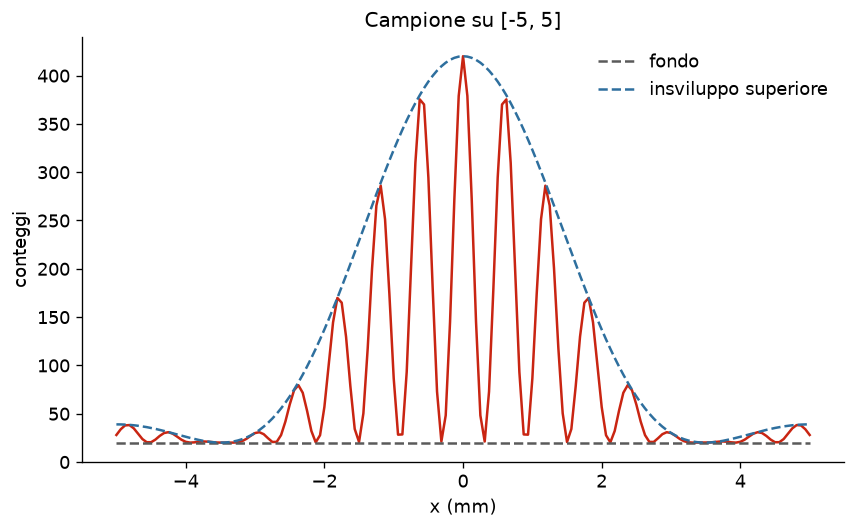

In [238]:
fig, ax = plt.subplots()
ax.plot(x, mu, color = ROSSO)
ax.plot(x, x*0 + B, color = GRIGIO ,ls="--", label=r"fondo")
ax.plot(x, B + I*E, color = AZZURRO , ls="--", label=r"insviluppo superiore")
ax.set(xlabel="x (mm)", ylabel="conteggi", title="Campione su [-5, 5]")
ax.legend()
plt.show()

In [239]:
#verifica
for i in range(len(x)):
    if mu[i] != mu[160-i]:
        print("non è simmetrica")
    elif(i==160):
        print("simmetrica")

for i in range(len(x)):
    if mu[i] < 0:
        print("error")

max = mu[0]
for i in mu:
        if i >= max:
            max = i
print("il valore max della funzione è: ", max)
print("essendo ", max, " un valore finito, allora la funzione è finita")

simmetrica
il valore max della funzione è:  420.0
essendo  420.0  un valore finito, allora la funzione è finita


Creiamo una simulazione

[ 4.69041576  5.56776436  6.40312424  6.8556546   5.09901951  5.29150262
  4.79583152  4.12310563  5.29150262  5.          5.          5.91607978
  6.          4.69041576  4.47213595  4.69041576  4.          5.19615242
  4.69041576  4.58257569  5.29150262  5.47722558  5.          5.47722558
  5.19615242  4.35889894  4.69041576  5.          4.35889894  4.24264069
  5.19615242  4.69041576  4.47213595  5.19615242  4.47213595  5.19615242
  4.69041576  3.87298335  4.47213595  6.40312424  8.30662386  9.05538514
  8.30662386  7.34846923  7.68114575  5.65685425  4.79583152  5.65685425
  6.70820393  8.94427191 12.28820573 13.         12.84523258 10.44030651
  8.36660027  5.65685425  4.12310563  6.244998   11.53256259 14.56021978
 16.15549442 16.64331698 15.93737745 12.40967365  9.43398113  5.19615242
  5.19615242  9.94987437 13.85640646 17.69180601 18.70828693 19.39071943
 17.1464282  12.28820573  8.66025404  3.87298335  6.40312424 11.78982612
 16.46207763 20.09975124 21.23676058 20.22374842 17

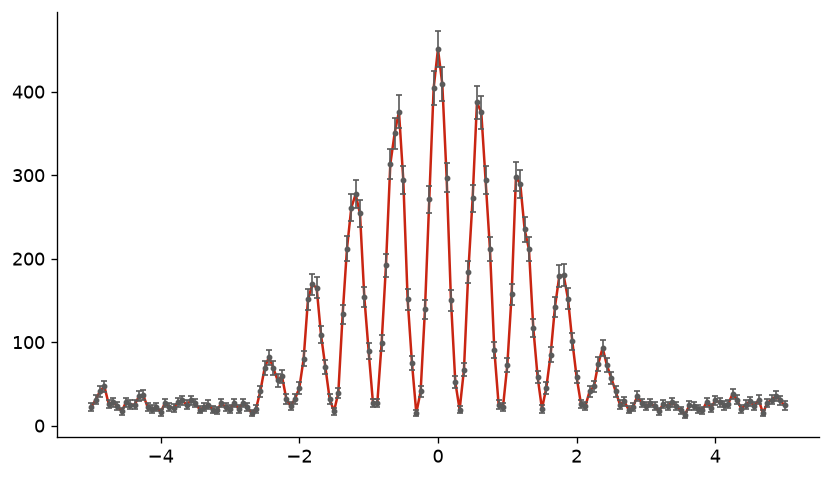

In [240]:
n = rng.poisson(mu)
#err = np.array
for i in n:
    if i < 1:
        err=1
    else: 
        err=np.sqrt(n)
fig, ax = plt.subplots()
ax.plot(x, n, color = ROSSO)
ax.errorbar(
    x,
    n,
    yerr=err,
    fmt="o",
    linestyle="none",
    color=GRIGIO,
    markersize=2.5,
    capsize=2,
    elinewidth=1.0,
)
print(err)
plt.show()


In [241]:
#conteggi centrali e mu
Nc=0
mu_c=0
for i in range(len(x)):
    if(np.absolute(x[i]) < 1.2):
        Nc += n[i]
        mu_c += mu[i]

print (Nc , mu_c , np.absolute(Nc - mu_c) , np.sqrt(mu_c))



7670 7649.413041897333 20.586958102667268 87.46092294217648


In [242]:
def simulation(x, rng):
    E = (np.sinc(alfa * x / np.pi))**2
    C = (np.cos(delta * x))**2
    mu = B + I * E * C
    n = rng.poisson(mu)
    Nc=0
    mu_c=0
    for i in range(len(x)):
        if(np.absolute(x[i]) < 1.2):
            Nc += n[i]
            mu_c += mu[i]

    return Nc

Nc_= np.arange(2000)
for i in range(2000):
    Nc_[i] = simulation(x,rng)

print(Nc_)


[7635 7623 7575 ... 7726 7585 7785]


In [255]:
#media, dev , ecc
media = np.mean(Nc_)
dev = np.std(Nc_ , ddof=1)
dev_media = dev / np.sqrt(2000)
scarto = (Nc_ - mu_c)/ mu_c

print (media, dev, dev_media, scarto , np.sqrt(mu_c))

7648.7655 89.09809057786991 1.9922938719755063 [-0.0018842  -0.00345295 -0.00972794 ...  0.01001214 -0.00842065
  0.01772515] 87.46092294217648


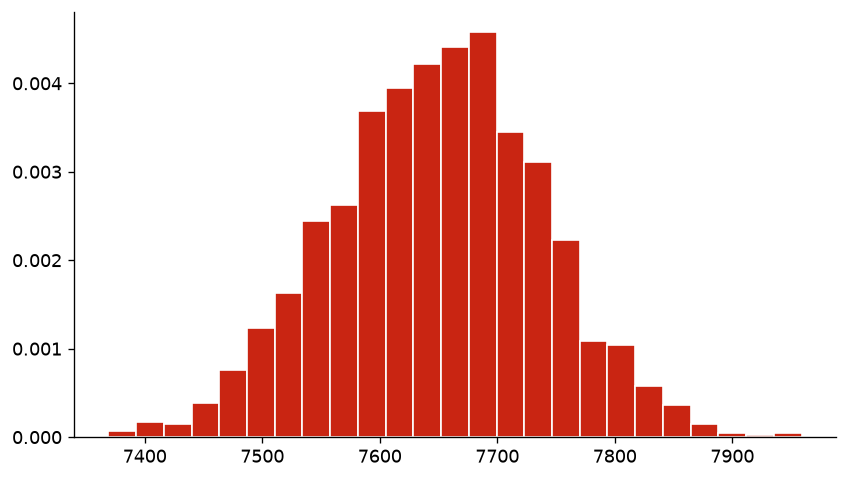

In [260]:
#istogramma 
max = np.max(Nc_)
min = np.min(Nc_)
fig,ax = plt.subplots()
ax.hist(Nc_ , bins=25, density=True, color=ROSSO, edgecolor="white")
plt.show()
